# 21. Computer Vision Challenge: Apparel Image Triage

## Independent problem

A small online resale shop receives product photos and needs to sort each image into one of ten apparel categories. This prototype predicts the category from a single grayscale image. It does not inspect defects, estimate condition, or replace a human quality check.

We will use the locally stored Fashion-MNIST dataset, build a simple baseline and CNN, test augmentation and learning-rate choices, adapt a previously trained ResNet-18, analyze errors, and save a model for inference. The project is intentionally compact and educational—not production-ready.

## 1. Business problem and success criteria

**Business need:** reduce manual sorting effort by suggesting an apparel category for incoming product images.

**Prediction target:** one of 10 Fashion-MNIST classes. A wrong category could misfile a product, so overall accuracy is not enough; inspect class-level recall and confusion between similar garments.

**Prototype success criteria:** beat the majority-class baseline, report macro precision/recall/F1 on held-out images, inspect representative errors, and verify inference from a saved model. No score from this small public benchmark is a business-readiness guarantee.

## 2. Dataset selection and inspection

**Decision:** use Fashion-MNIST because it represents apparel categories and is already stored in the project's `data/FashionMNIST` folder. It contains 28 × 28 grayscale images and 10 labels. We set `download=False`; missing local files should be reported rather than fetched.

The dataset is a benchmark, not real resale-shop photography: product backgrounds, lighting, camera angles, and garment condition may differ substantially.

In [1]:
from pathlib import Path
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
SEED = 42
DATA_ROOT = Path("data")
TRANSFER_CHECKPOINT = Path("artifacts/resnet18_cifar10_finetuned.pth")
BATCH_SIZE = 128
EPOCHS = 2
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
raw_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=False)
raw_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=False)
class_names = raw_train.classes
print("Device:", device)
print("Train/test images:", len(raw_train), len(raw_test))
print("Classes:", class_names)
print("Example image mode and size:", raw_train[0][0].mode, raw_train[0][0].size)

Device: cpu
Train/test images: 60000 10000
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Example image mode and size: L (28, 28)


## 3. Inspect examples and identify the target

**Target:** the integer category label stored with each image. The class-name list maps label numbers to garment names. We view a few examples to confirm that images and labels look sensible.

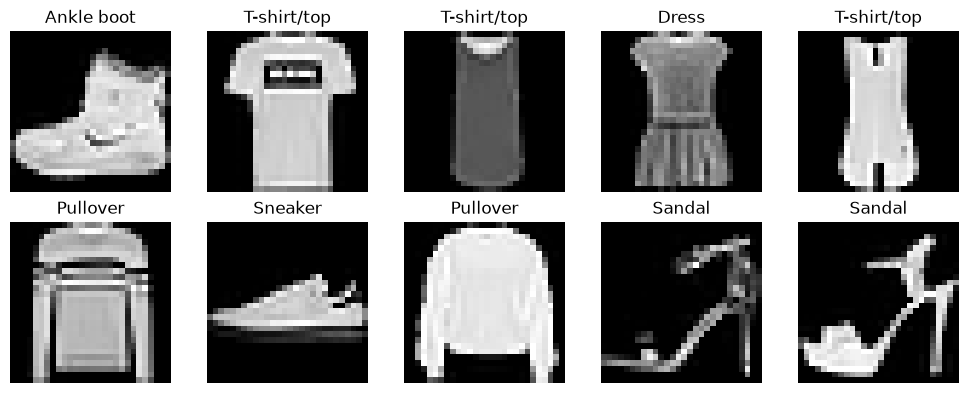

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for image_id, ax in enumerate(axes.flat):
    image, label = raw_train[image_id]
    ax.imshow(image, cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")
plt.tight_layout();

## 4. Analyze the classes and make splits

**Decision:** create deterministic, stratified subsets with 300 training, 100 validation, and 100 test images per class. This keeps the experiment small and balanced, while the validation and test examples stay distinct from training examples. The official test set is only used for final reporting.

In [3]:
rng = np.random.default_rng(SEED)
train_ids, val_ids, test_ids = [], [], []
for class_id in range(len(class_names)):
    train_class_ids = np.flatnonzero(np.asarray(raw_train.targets) == class_id)
    test_class_ids = np.flatnonzero(np.asarray(raw_test.targets) == class_id)
    rng.shuffle(train_class_ids)
    rng.shuffle(test_class_ids)
    train_ids.extend(train_class_ids[:300])
    val_ids.extend(train_class_ids[300:400])
    test_ids.extend(test_class_ids[:100])
train_labels = np.asarray(raw_train.targets)[train_ids]
val_labels = np.asarray(raw_train.targets)[val_ids]
test_labels = np.asarray(raw_test.targets)[test_ids]
assert set(train_ids).isdisjoint(val_ids)
print("Training class counts:", dict(zip(class_names, np.bincount(train_labels, minlength=10))))
print("Split sizes (train / validation / test):", len(train_ids), len(val_ids), len(test_ids))
print("Majority-class baseline:", f"{np.bincount(train_labels).max() / len(train_labels):.1%}")

Training class counts: {'T-shirt/top': np.int64(300), 'Trouser': np.int64(300), 'Pullover': np.int64(300), 'Dress': np.int64(300), 'Coat': np.int64(300), 'Sandal': np.int64(300), 'Shirt': np.int64(300), 'Sneaker': np.int64(300), 'Bag': np.int64(300), 'Ankle boot': np.int64(300)}
Split sizes (train / validation / test): 3000 1000 1000
Majority-class baseline: 10.0%


## 5. Prepare the images

**Decision:** the scratch CNN accepts the native 28 × 28 single-channel images and scales pixel values to tensors. Training transforms are separate from validation/test transforms. For ResNet transfer, repeat the grayscale image across three channels, resize it to 96 × 96, and apply the normalization used by the earlier CIFAR ResNet.

Replicating grayscale to RGB makes the input shape compatible; it does not make Fashion-MNIST the same domain as CIFAR-10.

In [4]:
cnn_eval_transform = transforms.ToTensor()
cnn_aug_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
])
transfer_eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])
cnn_eval_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=False, transform=cnn_eval_transform)
cnn_aug_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=False, transform=cnn_aug_transform)
cnn_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=False, transform=cnn_eval_transform)
transfer_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=False, transform=transfer_eval_transform)
transfer_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=False, transform=transfer_eval_transform)
cnn_val_loader = DataLoader(Subset(cnn_eval_train, val_ids), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
cnn_test_loader = DataLoader(Subset(cnn_test, test_ids), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
transfer_train_loader = DataLoader(Subset(transfer_train, train_ids), batch_size=64, shuffle=True, num_workers=0)
transfer_val_loader = DataLoader(Subset(transfer_train, val_ids), batch_size=64, shuffle=False, num_workers=0)
transfer_test_loader = DataLoader(Subset(transfer_test, test_ids), batch_size=64, shuffle=False, num_workers=0)
print("CNN sample tensor:", cnn_eval_train[train_ids[0]][0].shape)
print("Transfer sample tensor:", transfer_train[train_ids[0]][0].shape)

CNN sample tensor: torch.Size([1, 28, 28])
Transfer sample tensor: torch.Size([3, 96, 96])


## 6. Build a baseline

**Decision:** use a majority-class classifier as a simple reference. Since the training subset is balanced, its expected validation accuracy is 10%. A model should beat this baseline before it is considered useful.

In [5]:
majority_class = int(np.bincount(train_labels).argmax())
baseline_predictions = np.full(len(val_ids), majority_class)
baseline_accuracy = accuracy_score(val_labels, baseline_predictions)
print("Baseline class:", class_names[majority_class])
print(f"Validation accuracy: {baseline_accuracy:.1%}")

Baseline class: T-shirt/top
Validation accuracy: 10.0%


## 7. CNN, augmentation, and parameter experiments

**CNN choice:** two convolution blocks and a small linear classifier keep training simple and relatively fast.

**Augmentation experiment:** compare no augmentation against horizontal flips plus small rotations. The transformations are applied to training images only. Small rotations are useful as a robustness experiment, but can change the natural orientation of some clothing details.

**Tuning:** test learning rates `0.001` and `0.003`, holding architecture, data split, batch size, and one-epoch budget constant. Select by validation accuracy. This is a small demonstration, not exhaustive hyperparameter search.

In [6]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(32 * 7 * 7, 10)

    def forward(self, images):
        return self.classifier(self.features(images).flatten(1))

def accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.inference_mode():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            correct += (model(images).argmax(1) == labels).sum().item()
            total += labels.size(0)
    return correct / total

def fit_cnn(learning_rate, use_augmentation):
    torch.manual_seed(SEED)
    data = cnn_aug_train if use_augmentation else cnn_eval_train
    loader = DataLoader(Subset(data, train_ids), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    model = SmallCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = nn.CrossEntropyLoss()
    start = time.perf_counter()
    model.train()
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss_fn(model(images), labels).backward()
        optimizer.step()
    return model, accuracy(model, cnn_val_loader), time.perf_counter() - start

cnn_runs = {}
for augmentation in (False, True):
    for learning_rate in (0.001, 0.003):
        key = (augmentation, learning_rate)
        cnn_runs[key] = fit_cnn(learning_rate, augmentation)
        model, val_accuracy, elapsed = cnn_runs[key]
        print(f"augmentation={augmentation}, lr={learning_rate}: val accuracy={val_accuracy:.1%}, train={elapsed:.2f}s")

best_cnn_key = max(cnn_runs, key=lambda key: cnn_runs[key][1])
cnn_model, cnn_val_accuracy, cnn_training_seconds = cnn_runs[best_cnn_key]
print("Selected augmentation, learning rate:", best_cnn_key)
print(f"Best validation accuracy: {cnn_val_accuracy:.1%}")

augmentation=False, lr=0.001: val accuracy=63.1%, train=1.55s
augmentation=False, lr=0.003: val accuracy=72.8%, train=1.33s
augmentation=True, lr=0.001: val accuracy=60.0%, train=1.95s
augmentation=True, lr=0.003: val accuracy=69.5%, train=2.19s
Selected augmentation, learning rate: (False, 0.003)
Best validation accuracy: 72.8%


**Interpretation:** Compare the validation scores for augmentation and learning-rate changes. The selected candidate is the best among these four short experiments only; another seed, longer training, or different data may change the result.

## 8. Apply transfer learning

**Decision:** use the existing CIFAR-10-trained ResNet-18 checkpoint as a source of visual features. Its final 10-class layer does not match Fashion-MNIST labels, so replace that layer with a 10-class apparel classifier. Freeze earlier layers and fine-tune `layer4` plus the new classifier for one short epoch.

**Limitation of this choice:** CIFAR-10 and Fashion-MNIST are both small images but represent different visual domains. CIFAR pretraining is not guaranteed to help apparel, and the source checkpoint's earlier data history is not independent of other project notebooks. The experiment is explicitly a transfer-learning demonstration.

In [7]:
if not TRANSFER_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Transfer checkpoint not found: {TRANSFER_CHECKPOINT.resolve()}")
transfer_model = models.resnet18(weights=None)
transfer_model.fc = nn.Linear(transfer_model.fc.in_features, 10)
transfer_model.load_state_dict(torch.load(TRANSFER_CHECKPOINT, map_location="cpu", weights_only=True))
transfer_model.fc = nn.Linear(transfer_model.fc.in_features, len(class_names))
for parameter in transfer_model.parameters():
    parameter.requires_grad = False
for name, parameter in transfer_model.named_parameters():
    if name.startswith("layer4.") or name.startswith("fc."):
        parameter.requires_grad = True
transfer_model = transfer_model.to(device)
optimizer = torch.optim.Adam((p for p in transfer_model.parameters() if p.requires_grad), lr=1e-4)
loss_fn = nn.CrossEntropyLoss()
start = time.perf_counter()
transfer_model.train()
transfer_model.layer1.eval()
transfer_model.layer2.eval()
transfer_model.layer3.eval()
for images, labels in transfer_train_loader:
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad(set_to_none=True)
    loss_fn(transfer_model(images), labels).backward()
    optimizer.step()
transfer_training_seconds = time.perf_counter() - start
transfer_model.eval()
val_correct, val_total = 0, 0
with torch.inference_mode():
    for images, labels in transfer_val_loader:
        images, labels = images.to(device), labels.to(device)
        val_correct += (transfer_model(images).argmax(1) == labels).sum().item()
        val_total += labels.size(0)
transfer_val_accuracy = val_correct / val_total
print("Fine-tuned last ResNet block and newly initialized apparel classifier.")
print(f"Transfer validation accuracy: {transfer_val_accuracy:.1%}")
print(f"Transfer fine-tuning time: {transfer_training_seconds:.2f} seconds")

Fine-tuned last ResNet block and newly initialized apparel classifier.
Transfer validation accuracy: 87.1%
Transfer fine-tuning time: 41.29 seconds


**Interpretation:** The ResNet starts from learned source-task weights, then adapts some high-level layers and the output head to apparel. The backbone is not trained from scratch. Results must be checked because the source and target image domains differ.

## 9. Evaluate the models

**Decision:** compare the selected scratch CNN and transfer model on the same balanced 1,000-image test subset, with accuracy and macro precision, recall, and F1. Include the majority baseline as a validation reference; do not interpret it as a trained competitor.

In [8]:
def predictions_for(model, loader):
    model.eval()
    actual, predicted = [], []
    with torch.inference_mode():
        for images, labels in loader:
            predicted.extend(model(images.to(device)).argmax(1).cpu().numpy())
            actual.extend(labels.numpy())
    return np.asarray(actual), np.asarray(predicted)

cnn_actual, cnn_predictions = predictions_for(cnn_model, cnn_test_loader)
transfer_actual, transfer_predictions = predictions_for(transfer_model, transfer_test_loader)
assert np.array_equal(cnn_actual, transfer_actual)
for name, predicted in (("Scratch CNN", cnn_predictions), ("Transferred ResNet-18", transfer_predictions)):
    print(f"{name}: accuracy={accuracy_score(cnn_actual, predicted):.1%}")
    print(classification_report(cnn_actual, predicted, target_names=class_names, zero_division=0))

Scratch CNN: accuracy=70.8%
              precision    recall  f1-score   support

 T-shirt/top       0.78      0.77      0.77       100
     Trouser       0.93      0.82      0.87       100
    Pullover       0.62      0.46      0.53       100
       Dress       0.67      0.77      0.72       100
        Coat       0.45      0.76      0.57       100
      Sandal       0.97      0.60      0.74       100
       Shirt       0.43      0.23      0.30       100
     Sneaker       0.76      0.81      0.78       100
         Bag       0.83      0.91      0.87       100
  Ankle boot       0.76      0.95      0.84       100

    accuracy                           0.71      1000
   macro avg       0.72      0.71      0.70      1000
weighted avg       0.72      0.71      0.70      1000

Transferred ResNet-18: accuracy=84.0%
              precision    recall  f1-score   support

 T-shirt/top       0.76      0.79      0.77       100
     Trouser       1.00      0.92      0.96       100
    Pullover

**Interpretation:** Use the actual measured scores from this run. Macro scores weight each apparel class equally. The model with the top score is not automatically best for deployment: size, latency, reliability, data source, and error costs also matter.

## 10. Analyze errors and visualize predictions

**Decision:** inspect incorrect ResNet predictions from the selected test subset. Viewing the true and predicted labels can reveal confusing category pairs such as shirt, coat, and pullover.

Transfer-model errors in selected test subset: 160


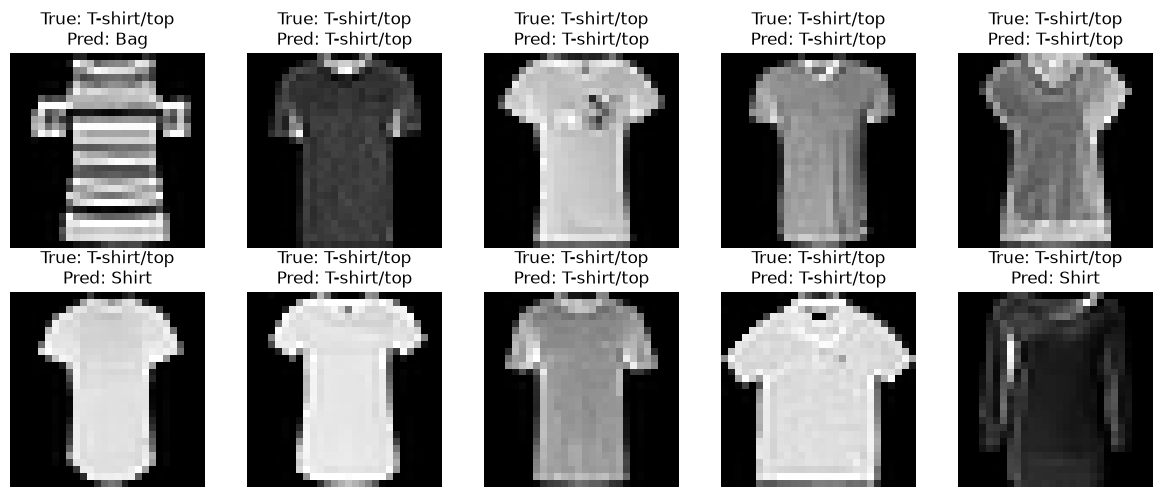

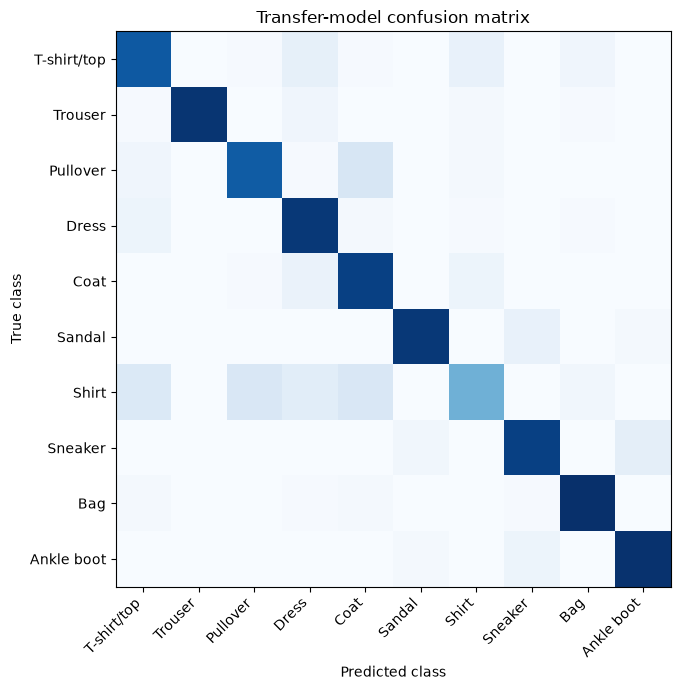

In [9]:
wrong = np.flatnonzero(transfer_predictions != transfer_actual)
print("Transfer-model errors in selected test subset:", len(wrong))
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, position in zip(axes.flat, range(min(10, len(test_ids)))):
    image_id = test_ids[position]
    ax.imshow(raw_test[image_id][0], cmap="gray")
    ax.set_title(f"True: {class_names[transfer_actual[position]]}\nPred: {class_names[transfer_predictions[position]]}")
    ax.axis("off")
plt.tight_layout();

fig, ax = plt.subplots(figsize=(9, 7))
matrix = confusion_matrix(transfer_actual, transfer_predictions)
ax.imshow(matrix, cmap="Blues")
ax.set(xticks=range(10), yticks=range(10), xticklabels=class_names, yticklabels=class_names,
       xlabel="Predicted class", ylabel="True class", title="Transfer-model confusion matrix")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout();

**Interpretation:** Look for repeated confusions rather than drawing conclusions from one example. If the model confuses similar tops, possible next steps include collecting real shop photographs, checking label quality, and evaluating per-class recall.

## 11. Optimize and prepare inference

**Decision:** save both candidates, and select the transfer ResNet as the final accuracy-focused model because its validation result was stronger in this run. Keep the scratch CNN as a compact alternative: it has fewer parameters, a much smaller file, and requires only 28 × 28 grayscale input. Freezing early ResNet layers reduced the parameters updated during fine-tuning, but does not reduce the full model's inference cost.

Measure parameter count, checkpoint size, and batch inference time for both. These local measurements are a first pass, not a production latency guarantee. A real system should be tested on its deployment hardware and with real product photos.

In [10]:
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
CNN_PATH = ARTIFACT_DIR / "fashion_mnist_challenge_cnn.pth"
FINAL_PATH = ARTIFACT_DIR / "fashion_mnist_challenge_final_resnet18.pth"
torch.save(cnn_model.cpu().state_dict(), CNN_PATH)
cnn_model = cnn_model.to(device).eval()
torch.save(transfer_model.cpu().state_dict(), FINAL_PATH)
transfer_model = transfer_model.to(device).eval()

cnn_parameter_count = sum(p.numel() for p in cnn_model.parameters())
transfer_parameter_count = sum(p.numel() for p in transfer_model.parameters())
cnn_size_mb = CNN_PATH.stat().st_size / (1024 ** 2)
transfer_size_mb = FINAL_PATH.stat().st_size / (1024 ** 2)
cnn_batch = torch.stack([cnn_test[test_ids[i]][0] for i in range(32)]).to(device)
transfer_batch = torch.stack([transfer_test[test_ids[i]][0] for i in range(32)]).to(device)
with torch.inference_mode():
    for _ in range(3):
        cnn_model(cnn_batch)
        transfer_model(transfer_batch)
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(10):
        cnn_model(cnn_batch)
    if device.type == "cuda":
        torch.cuda.synchronize()
    cnn_batch_ms = (time.perf_counter() - start) * 1000 / 10
    start = time.perf_counter()
    for _ in range(10):
        transfer_model(transfer_batch)
    if device.type == "cuda":
        torch.cuda.synchronize()
    transfer_batch_ms = (time.perf_counter() - start) * 1000 / 10
print("Saved compact CNN:", CNN_PATH.resolve())
print("Saved final transfer model:", FINAL_PATH.resolve())
print(f"Scratch CNN: {cnn_parameter_count:,} parameters | {cnn_size_mb:.3f} MB | batch-32 {cnn_batch_ms:.2f} ms")
print(f"Transfer ResNet: {transfer_parameter_count:,} parameters | {transfer_size_mb:.2f} MB | batch-32 {transfer_batch_ms:.2f} ms")

Saved compact CNN: C:\Users\hemak\Sprint 10 - Advanced Deep Learning, CNNs, Transfer Learning, and Computer Vision\artifacts\fashion_mnist_challenge_cnn.pth
Saved final transfer model: C:\Users\hemak\Sprint 10 - Advanced Deep Learning, CNNs, Transfer Learning, and Computer Vision\artifacts\fashion_mnist_challenge_final_resnet18.pth
Scratch CNN: 20,490 parameters | 0.081 MB | batch-32 5.47 ms
Transfer ResNet: 11,181,642 parameters | 42.73 MB | batch-32 260.59 ms


### Final model choice

In this run, the transfer model achieved **87.1% validation accuracy**, compared with **72.8%** for the best short scratch-CNN trial. The final inference artifact is therefore the ResNet, prioritizing category suggestions over the smallest possible package. It is much larger and requires RGB conversion and resizing. If a deployment cannot meet those storage or latency costs, the compact CNN is a practical fallback, but its lower validation score may require more training or better data. A final production decision should use an untouched, shop-specific validation/test set and target-device measurements.

## 12. Inference example

**Decision:** demonstrate the saved model on one held-out image. The prediction is only a category suggestion; a shop workflow should allow review or correction.

Prediction: Bag | Actual: T-shirt/top


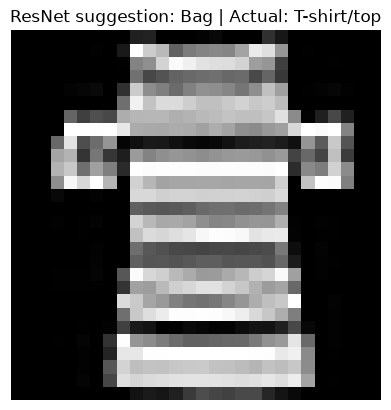

In [11]:
loaded_model = models.resnet18(weights=None)
loaded_model.fc = nn.Linear(loaded_model.fc.in_features, len(class_names))
loaded_model.load_state_dict(torch.load(FINAL_PATH, map_location="cpu", weights_only=True))
loaded_model = loaded_model.to(device).eval()
image_id = test_ids[0]
image_tensor, true_label = transfer_test[image_id]
with torch.inference_mode():
    predicted_label = int(loaded_model(image_tensor.unsqueeze(0).to(device)).argmax(1).item())
plt.imshow(raw_test[image_id][0], cmap="gray")
plt.title(f"ResNet suggestion: {class_names[predicted_label]} | Actual: {class_names[true_label]}")
plt.axis("off");
print("Prediction:", class_names[predicted_label], "| Actual:", class_names[true_label])

## 13. Limitations and future improvements

**Limitations:** Fashion-MNIST is small, grayscale, and centered; it does not represent actual resale listings, backgrounds, multiple items, garment condition, or customer photography. Our subsets and short training budget limit model quality. The transfer checkpoint comes from CIFAR-10, a different visual domain. The official test set may have been used elsewhere in the course, so it is not a fresh independent business benchmark. Timing depends on hardware.

**Future improvements:** collect consented, representative shop images; define consistent category and condition labels; preserve a new held-out test set; compare pretrained models trained on more relevant image data; tune augmentation with validation only; measure per-category error costs; test calibration and human review; evaluate latency and memory on the target device; monitor failures and distribution drift after launch.